# 13. Modal Expansion Analysis: Bloch Mode & Plane-Wave Coupling Amplitudes

## Physical Motivation & Learning Objectives
Understanding how energy distributes between modal channels clarifies resonance excitation. In this tutorial:
1. We compute Bloch mode excitation amplitudes (`plotting.BM_amplitudes`).
2. We compute plane-wave diffraction order distributions (`plotting.PW_amplitudes`).
3. We evaluate evanescent field decay figures of merit (`plotting.evanescent_merit`).


**Legacy example.** This notebook reproduces `simo_052-plotting_amplitudes.py` from the original EMUstack. It uses that script's inputs unchanged; T, R and A then agree with legacy EMUstack to 3e-10 (checked in `benchmarks/parity/`, `examples/` version).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



## Grating Setup


In [2]:
wavelengths = np.linspace(1500, 1600, 10)
period = 700.0  # nm

light_list = [objects.Light(wl, max_order_PWs=6, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
absorber    = objects.ThinFilm(period, height_nm=10.0, material=materials.Material(1.0 + 0.05j), world_1d=True, loss=True)

grating = objects.NanoStruct(
    '1D_array', period, int(round(0.75 * period)),
    height_nm=2900.0,
    background=materials.Material(1.46),
    inclusion_a=materials.Material(3.61),
    loss=True, lc_bkg=0.005, plt_msh=False
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_abs = absorber.calc_modes(light)
    sim_grt = grating.calc_modes(light)
    stk = Stack((sim_sub, sim_abs, sim_grt, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

stacks_list = [simulate_stack(light) for light in light_list]


## Modal Amplitudes & Evanescent Merit Analysis


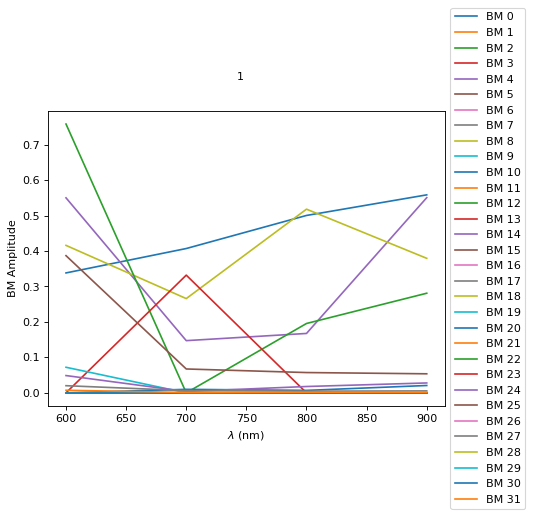

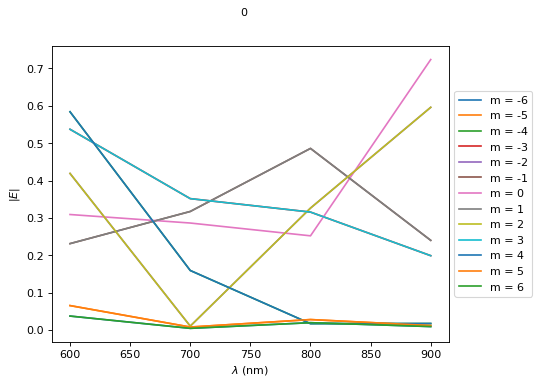

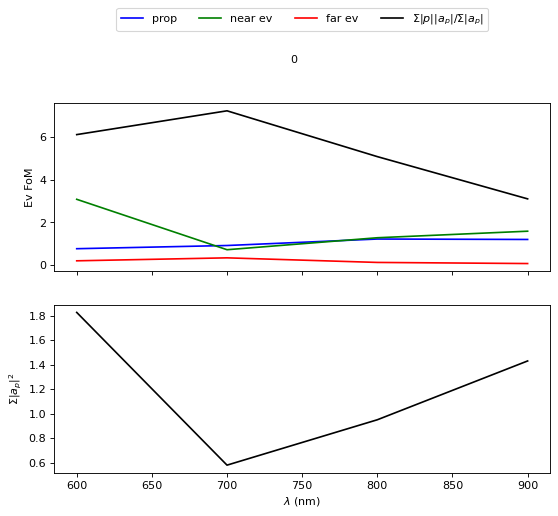

In [3]:
figs_bm = plotting.BM_amplitudes(stacks_list, lay_interest=2, chosen_BMs=[0, 1, 2, 3, 4, 5],
                                 save_pdf=False)
plt.show()

figs_pw = plotting.PW_amplitudes(stacks_list, save_pdf=False)
plt.show()

figs_ev = plotting.evanescent_merit(stacks_list, save_pdf=False)
plt.show()


## Physical Interpretation
- Amplitudes identify which Bloch modes couple directly to incident radiation and carry net Poynting flux.
- Evanescent decay figures of merit quantify the penetration depth of near-field orders into neighboring layers.
